# 09. Wyjaśnialność (xAI): SHAP

**Krok procesu:** 10. xAI.

Model widzi tylko liczby (współrzędne punktów dłoni), więc Grad-CAM nie ma tu sensu, bo nie ma obrazu i warstw
konwolucyjnych. Używamy SHAP: dla jednej predykcji mówi, ile każda cecha (np. `y8`, współrzędna y czubka palca
wskazującego) przesunęła prawdopodobieństwo danej klasy w górę albo w dół, względem średniej predykcji na tle.

Metoda: `PermutationExplainer` z biblioteki `shap`, model traktowany jako czarna skrzynka (`predict_proba`).
Tło (background): 200 losowych dłoni z treningu. Wyjaśniamy 300 dłoni z val, po 50 z każdej klasy.

Sumujemy wartości |SHAP| dla x i y tego samego punktu. Dzięki temu możemy narysować ważność na szkielecie dłoni.

In [1]:
import sys
sys.path.insert(0, "../src")

import json
import pickle
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap

from features import normalise
from labels import HAND_EDGES
from pipeline import MODELS, PREPROCESS, feature_names, load_split

FIG = Path("../reports/figures")
sns.set_theme(style="white")
gates = json.loads(Path("../experiments/gates.json").read_text())
prep_name = gates["final"]["preprocess"]
prep = PREPROCESS[prep_name]
model = pickle.load(open(MODELS / "final.pkl", "rb"))
names = feature_names(prep_name)
LANDMARK_PL = ["nadgarstek", "kciuk CMC", "kciuk MCP", "kciuk IP", "kciuk czubek",
               "wskazujący MCP", "wskazujący PIP", "wskazujący DIP", "wskazujący czubek",
               "środkowy MCP", "środkowy PIP", "środkowy DIP", "środkowy czubek",
               "serdeczny MCP", "serdeczny PIP", "serdeczny DIP", "serdeczny czubek",
               "mały MCP", "mały PIP", "mały DIP", "mały czubek"]

COUNT_PL = {0: "0 palców", 1: "1 palec", 2: "2 palce", 3: "3 palce", 4: "4 palce", 5: "5 palców"}

lm_tr, y_tr, _ = load_split("train")
lm_va, y_va, d_va = load_split("val")
rng = np.random.default_rng(0)
background = prep(lm_tr[rng.choice(len(lm_tr), 200, replace=False)])
idx = np.concatenate([rng.choice(np.where(y_va == c)[0], 50, replace=False) for c in range(6)])
X_explain = prep(lm_va[idx])

/Users/jakub.wi/Documents/semestr7/projekt_WTUM/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
explainer = shap.PermutationExplainer(model.predict_proba, shap.maskers.Independent(background, max_samples=200), feature_names=names,
                                      seed=0)
sv = explainer(X_explain)  # values: (300 dłoni, cechy, 6 klas)
print(sv.values.shape)

PermutationExplainer explainer:  54%|█████▍    | 162/300 [00:00<?, ?it/s]

PermutationExplainer explainer:  55%|█████▌    | 165/300 [00:10<00:05, 23.31it/s]

PermutationExplainer explainer:  56%|█████▌    | 168/300 [00:10<00:07, 18.47it/s]

PermutationExplainer explainer:  57%|█████▋    | 170/300 [00:10<00:07, 17.53it/s]

PermutationExplainer explainer:  57%|█████▋    | 172/300 [00:10<00:07, 17.04it/s]

...

PermutationExplainer explainer:  99%|█████████▊| 296/300 [00:18<00:00, 16.13it/s]

PermutationExplainer explainer:  99%|█████████▉| 298/300 [00:18<00:00, 16.12it/s]

PermutationExplainer explainer: 100%|██████████| 300/300 [00:18<00:00, 16.10it/s]

PermutationExplainer explainer: 301it [00:18,  7.45it/s]                         

(300, 42, 6)


## Ważność punktów dłoni dla każdej liczby palców (globalnie)

Dla każdej klasy bierzemy dłonie z tej klasy i średnie |SHAP| tej klasy. Wielkość i kolor kółka to ważność punktu.
Szkielet to typowa dłoń z tej klasy (medoid, czyli prawdziwa dłoń najbliższa średniej). Średniej dłoni nie da się
narysować, bo lewe i prawe dłonie się znoszą.

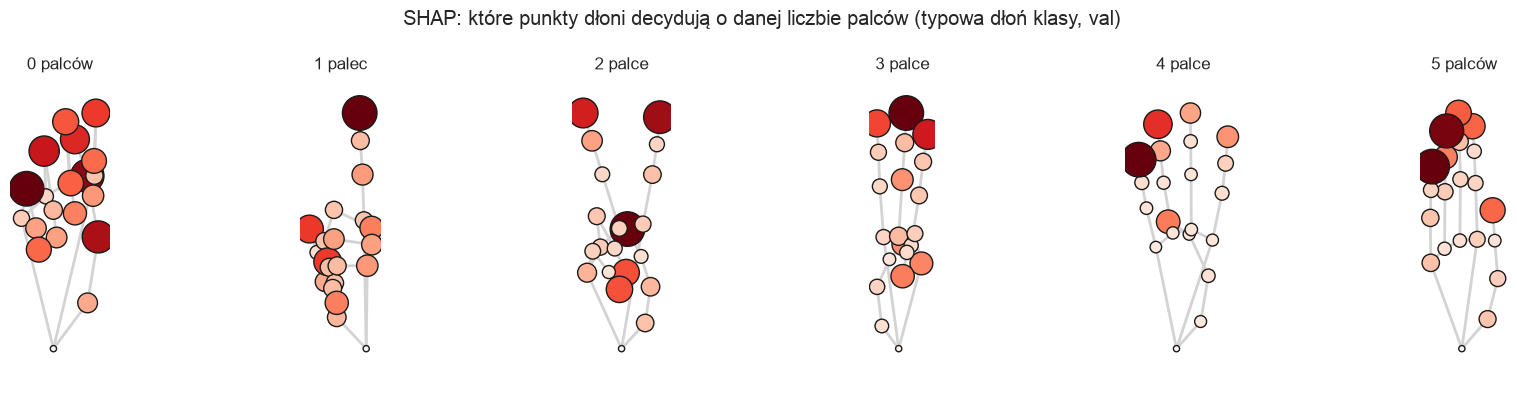

In [3]:
def landmark_importance(values):
    """(n, cechy) -> (21,) średnie |SHAP| sumowane po x i y punktu."""
    pts = np.abs(values[:, :42]).reshape(len(values), 21, 2).sum(-1)
    return pts.mean(0)

norm_va = normalise(lm_va[idx])
fig, axes = plt.subplots(1, 6, figsize=(18, 4))
imps = {}
for c, ax in enumerate(axes):
    rows = y_va[idx] == c
    imp = landmark_importance(sv.values[rows, :, c])
    imps[c] = imp
    hands_c = norm_va[rows]
    hand = hands_c[np.linalg.norm(hands_c - hands_c.mean(0), axis=(1, 2)).argmin()]
    for a, b in HAND_EDGES:
        ax.plot(hand[[a, b], 0], -hand[[a, b], 1], color="lightgrey", lw=2, zorder=1)
    ax.scatter(hand[:, 0], -hand[:, 1], s=20 + 600 * imp / max(imp.max(), 1e-9), c=imp, cmap="Reds",
               edgecolor="k", zorder=2, vmin=0)
    ax.set_title(COUNT_PL[c]); ax.set_aspect("equal"); ax.axis("off"); ax.margins(0.15)
plt.suptitle("SHAP: które punkty dłoni decydują o danej liczbie palców (typowa dłoń klasy, val)")
plt.tight_layout(); plt.savefig(FIG / "xai_shap_landmarks_per_class.png", dpi=150); plt.show()

In [4]:
top = pd.DataFrame({COUNT_PL[c]: pd.Series(imps[c], index=LANDMARK_PL).nlargest(4).index.tolist() for c in range(6)})
top.index = [f"{i + 1}." for i in range(4)]
top

,0 palców,1 palec,2 palce,3 palce,4 palce,5 palców
1.,mały PIP,wskazujący czubek,kciuk czubek,środkowy czubek,mały czubek,mały czubek
2.,kciuk IP,kciuk czubek,wskazujący czubek,serdeczny czubek,serdeczny czubek,serdeczny czubek
3.,kciuk MCP,środkowy czubek,środkowy czubek,wskazujący czubek,kciuk czubek,środkowy czubek
4.,serdeczny PIP,środkowy MCP,serdeczny czubek,mały czubek,wskazujący czubek,wskazujący czubek


## Ważność cech w całym modelu

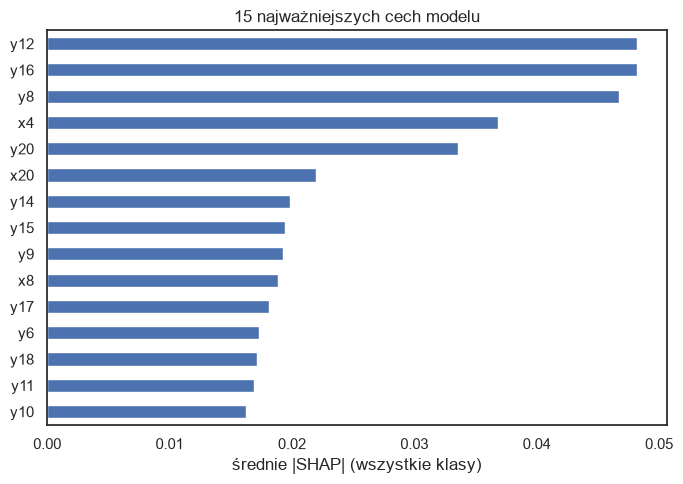

In [5]:
global_imp = pd.Series(np.abs(sv.values).mean((0, 2)), index=names).sort_values(ascending=False)
ax = global_imp.head(15)[::-1].plot.barh(figsize=(7, 5), color=sns.color_palette()[0])
ax.set(xlabel="średnie |SHAP| (wszystkie klasy)", title="15 najważniejszych cech modelu")
plt.tight_layout(); plt.savefig(FIG / "xai_shap_top_features.png", dpi=150); plt.show()

## Konkretne przykłady (lokalnie)

Na szkielecie konkretnej dłoni: czerwone punkty podnoszą prawdopodobieństwo przewidzianej klasy, niebieskie
je obniżają. Pokazujemy dwie dobrze rozpoznane dłonie i dwie pomyłki. Pomyłki są rzadkie (około 0.6% na val),
więc szukamy ich w całym val i wyjaśniamy osobno.

Pomyłki na val: 448 z 76669 (0.58%)


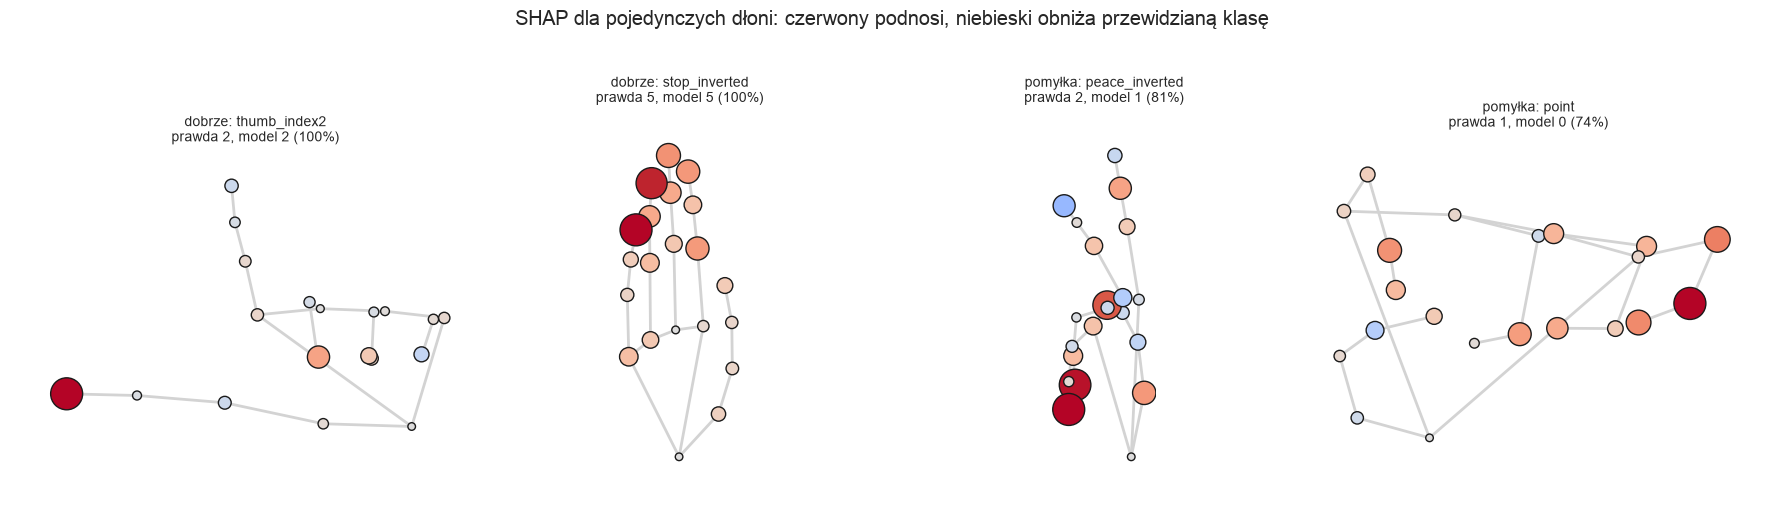

In [6]:
pred_all = model.predict(prep(lm_va))
wrong_all = np.where(pred_all != y_va)[0]
wrong_pick = np.random.default_rng(1).choice(wrong_all, 2, replace=False)
sv_wrong = explainer(prep(lm_va[wrong_pick]))

# Łączymy wyjaśnione dłonie: 300 z próbki i 2 pomyłki.
all_idx = np.concatenate([idx, wrong_pick])
all_values = np.concatenate([sv.values, sv_wrong.values])
all_X = prep(lm_va[all_idx])
pred, proba = model.predict(all_X), model.predict_proba(all_X)
norm_all = normalise(lm_va[all_idx])
y_all = y_va[all_idx]
correct = np.where(pred[:300] == y_all[:300])[0]
examples = [correct[y_all[correct] == 2][0], correct[y_all[correct] == 5][0], 300, 301]
print(f"Pomyłki na val: {len(wrong_all)} z {len(y_va)} ({len(wrong_all) / len(y_va):.2%})")

fig, axes = plt.subplots(1, len(examples), figsize=(4.5 * len(examples), 5))
for ax, i in zip(axes, examples):
    c = pred[i]
    contrib = all_values[i, :42, c].reshape(21, 2).sum(-1)
    hand = norm_all[i]
    for a, b in HAND_EDGES:
        ax.plot(hand[[a, b], 0], -hand[[a, b], 1], color="lightgrey", lw=2, zorder=1)
    lim = np.abs(contrib).max()
    ax.scatter(hand[:, 0], -hand[:, 1], s=30 + 500 * np.abs(contrib) / lim, c=contrib, cmap="coolwarm", vmin=-lim,
               vmax=lim, edgecolor="k", zorder=2)
    gest = d_va.label.iloc[all_idx[i]]
    kind = "pomyłka" if c != y_all[i] else "dobrze"
    ax.set_title(f"{kind}: {gest}\nprawda {y_all[i]}, model {c} ({proba[i, c]:.0%})", fontsize=10)
    ax.set_aspect("equal"); ax.axis("off"); ax.margins(0.15)
plt.suptitle("SHAP dla pojedynczych dłoni: czerwony podnosi, niebieski obniża przewidzianą klasę", y=1.02)
plt.tight_layout(); plt.savefig(FIG / "xai_shap_examples.png", dpi=150, bbox_inches="tight"); plt.show()

In [7]:
rows = []
for i in examples:
    c = pred[i]
    pts = pd.Series(all_values[i, :42, c].reshape(21, 2).sum(-1), index=LANDMARK_PL)
    rows.append({"gest": d_va.label.iloc[all_idx[i]], "prawda": y_all[i], "model": c,
                 "pewność": f"{proba[i, c]:.0%}", "drugi wybór": int(np.argsort(proba[i])[-2]),
                 "najmocniej za": ", ".join(pts.nlargest(2).index), "najmocniej przeciw": ", ".join(pts.nsmallest(2).index)})
pd.DataFrame(rows)

,gest,prawda,model,pewność,drugi wybór,najmocniej za,najmocniej przeciw
0,thumb_index2,2,2,100%,1,"kciuk czubek, środkowy czubek","mały czubek, wskazujący czubek"
1,stop_inverted,5,5,100%,2,"mały czubek, serdeczny czubek","nadgarstek, środkowy MCP"
2,peace_inverted,2,1,81%,2,"mały czubek, serdeczny czubek","środkowy czubek, środkowy MCP"
3,point,1,0,74%,1,"mały DIP, mały PIP","kciuk IP, środkowy PIP"


## Wnioski

- **Model patrzy na czubki palców.** Dla 3, 4 i 5 palców wszystkie cztery najważniejsze punkty to czubki.
  Dla 0 palców ważne są stawy (PIP, IP, MCP), bo w pięści czubki są schowane i model sprawdza zgięcie.
  To zgadza się z tym, jak liczy człowiek, więc model nie uczy się czegoś przypadkowego, np. położenia nadgarstka.
- **Dla 1 i 2 palców ważny jest kciuk.** Klasa 1 to m.in. `like` i `dislike` (sam kciuk), a 2 to `call`
  i `thumb_index`. Model musi rozróżnić, czy wyprostowany jest kciuk, czy wskazujący. To ten sam słaby punkt,
  który pokazały EDA i wyniki na gestach w 08.
- **Pomyłki są rzadkie: 448 z 76 669 dłoni val (0.58%).** W przykładzie `peace_inverted` (2 palce, model 1 z 81%)
  dłoń jest skierowana w dół. Środkowy palec ciągnie wynik w stronę 2, ale model i tak wybiera 1. Druga pomyłka
  (`point`, model 0 z 74%) to dłoń ułożona bokiem i mocno przechylona. Za pięścią głosują stawy małego palca,
  przeciw niej kciuk i środkowy palec, ale to nie wystarcza.
- **Wniosek dla telefonu:** pomyłki biorą się z nietypowej orientacji dłoni, a nie z jakości modelu.
  W aplikacji obrót klatki trzeba ustawić poprawnie (patrz `deploy/README.md`).
- Metoda permutacyjna wywołuje model setki razy na każdą dłoń. Dlatego wyjaśniamy zbalansowaną próbkę
  (po 50 dłoni na klasę), a nie całe val.